# Identifikasi Dataset Klasifikasi
**Nama:** Fahmi Saddam  |  **NIM:** 241011400848  
**Universitas Pamulang – S1 Teknik Informatika**

| No | Jenis Klasifikasi | Dataset | Tipe Data |
|---|---|---|---|
| 1 | Biner | Breast Cancer Wisconsin (Diagnostic) | Tabular (angka) |
| 2 | Multikelas | Fashion-MNIST | Image |
| 3 | Multilabel | Yeast | Tabular (angka) |

Untuk setiap dataset: asal dataset → identifikasi fitur & target → ubah ke DataFrame → jumlah data & variabel → tipe data (teks/image) → kesimpulan jenis klasifikasi → simpan ke CSV.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
pd.set_option("display.max_columns", 12)

---
# 1. Klasifikasi Biner — Breast Cancer Wisconsin (Diagnostic)

### Asal dataset
- **Sumber asli:** UCI Machine Learning Repository, *Breast Cancer Wisconsin (Diagnostic)* — https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- **Pembuat:** W. H. Wolberg, W. N. Street, O. L. Mangasarian (University of Wisconsin), 1993.
- **Cara ambil di notebook ini:** sudah tersedia di scikit-learn (`sklearn.datasets.load_breast_cancer`), jadi tidak perlu unduh. Salinannya juga ada di Kaggle.
- **Isi:** fitur dihitung dari citra digital hasil *fine needle aspirate* (FNA) massa payudara; menggambarkan karakteristik inti sel (radius, tekstur, perimeter, area, dst.).

In [2]:
from sklearn.datasets import load_breast_cancer

bunch = load_breast_cancer()

# Ubah ke DataFrame
X_bc = pd.DataFrame(bunch.data, columns=bunch.feature_names)   # FITUR
y_bc = pd.Series(bunch.target, name="target")                   # TARGET / LABEL
df_bc = pd.concat([X_bc, y_bc], axis=1)

df_bc.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,...,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,...,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,...,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,...,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,...,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,...,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
print("Jumlah data      :", df_bc.shape[0])
print("Jumlah variabel  :", df_bc.shape[1], "(", X_bc.shape[1], "fitur +", 1, "target )")
print("Missing value    :", int(df_bc.isnull().sum().sum()))
print("Tipe data        : tabular (angka), bukan teks / image")
print()
print("Daftar fitur:")
print(list(X_bc.columns))
print()
print("Arti target (0/1):", dict(enumerate(bunch.target_names)))
print()
print(y_bc.value_counts().rename(index=dict(enumerate(bunch.target_names))))

Jumlah data      : 569
Jumlah variabel  : 31 ( 30 fitur + 1 target )
Missing value    : 0
Tipe data        : tabular (angka), bukan teks / image

Daftar fitur:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Arti target (0/1): {0: np.str_('malignant'), 1: np.str_('benign')}

target
benign       357
malignant    212
Name: count, dtype: int64


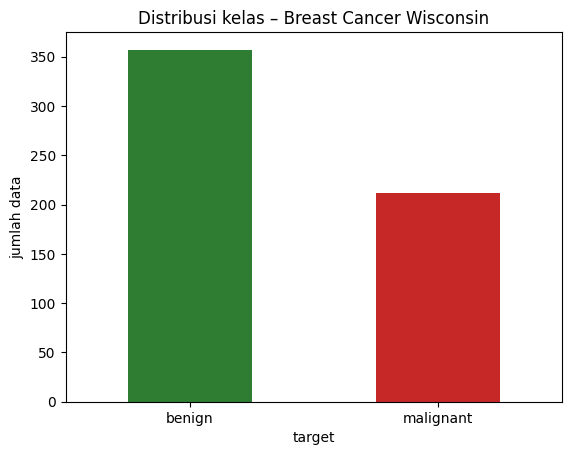

In [4]:
y_bc.map(dict(enumerate(bunch.target_names))).value_counts().plot(kind="bar", color=["#2e7d32", "#c62828"])
plt.title("Distribusi kelas – Breast Cancer Wisconsin")
plt.ylabel("jumlah data"); plt.xticks(rotation=0); plt.show()

### Identifikasi
- **Fitur (X):** 30 kolom numerik (mean, standard error, dan worst dari 10 ukuran inti sel).
- **Target (y):** kolom `target` → `0 = malignant` (ganas), `1 = benign` (jinak).
- **Tipe data:** tabular numerik.

### Kesimpulan
Target hanya memiliki **2 kelas** dan setiap data hanya punya **1 label** → **Klasifikasi Biner**.

In [5]:
df_bc.to_csv("data/breast_cancer_wisconsin.csv", index=False)
print("Tersimpan:", pd.read_csv("data/breast_cancer_wisconsin.csv").shape)

Tersimpan: (569, 31)


---
# 2. Klasifikasi Multikelas — Fashion-MNIST

### Asal dataset
- **Sumber asli:** Zalando Research — https://github.com/zalandoresearch/fashion-mnist (lisensi MIT)
- **Paper:** Xiao, Rasul, Vollgraf (2017), *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms*, arXiv:1708.07747.
- **Salinan lain:** Kaggle (`zalando-research/fashionmnist`), `tf.keras.datasets.fashion_mnist`, OpenML.
- **Cara ambil di notebook ini:** `fetch_openml("Fashion-MNIST")` (butuh koneksi internet).
- **Isi:** 70.000 gambar produk pakaian grayscale ukuran 28×28 piksel (60.000 train + 10.000 test) dalam 10 kelas.

> **Catatan GitHub:** CSV penuh (70.000 baris × 785 kolom) ±130 MB, melebihi batas 100 MB per file GitHub. Karena itu notebook ini menyimpan **sampel seimbang** (default 1.000 per kelas = 10.000 baris, ±17 MB). Ubah `SAMPLE_PER_CLASS = None` jika butuh data penuh.

In [6]:
from sklearn.datasets import fetch_openml

fm = fetch_openml("Fashion-MNIST", version=1, as_frame=True, parser="auto")

# Ubah ke DataFrame
X_fm = fm.data                                   # FITUR: 784 piksel (28x28)
y_fm = fm.target.astype(int).rename("label")     # TARGET: 0-9
df_fm = pd.concat([X_fm, y_fm], axis=1)

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
df_fm.iloc[:5, [0, 1, 2, -2, -1]]

,pixel1,pixel2,pixel3,pixel784,label
0,0,0,0,0,9
1,0,0,0,0,0
2,0,0,0,0,0
3,0,0,0,0,3
4,0,0,0,0,0


In [7]:
print("Jumlah data      :", df_fm.shape[0])
print("Jumlah variabel  :", df_fm.shape[1], "(", X_fm.shape[1], "fitur piksel +", 1, "target )")
print("Missing value    :", int(df_fm.isnull().sum().sum()))
print("Tipe data        : IMAGE (28x28 piksel grayscale, nilai 0-255)")
print()
print(y_fm.map(dict(enumerate(class_names))).value_counts())

Jumlah data      : 70000
Jumlah variabel  : 785 ( 784 fitur piksel + 1 target )
Missing value    : 0
Tipe data        : IMAGE (28x28 piksel grayscale, nilai 0-255)

label
Ankle boot     7000
T-shirt/top    7000
Dress          7000
Pullover       7000
Sneaker        7000
Sandal         7000
Trouser        7000
Shirt          7000
Coat           7000
Bag            7000
Name: count, dtype: int64


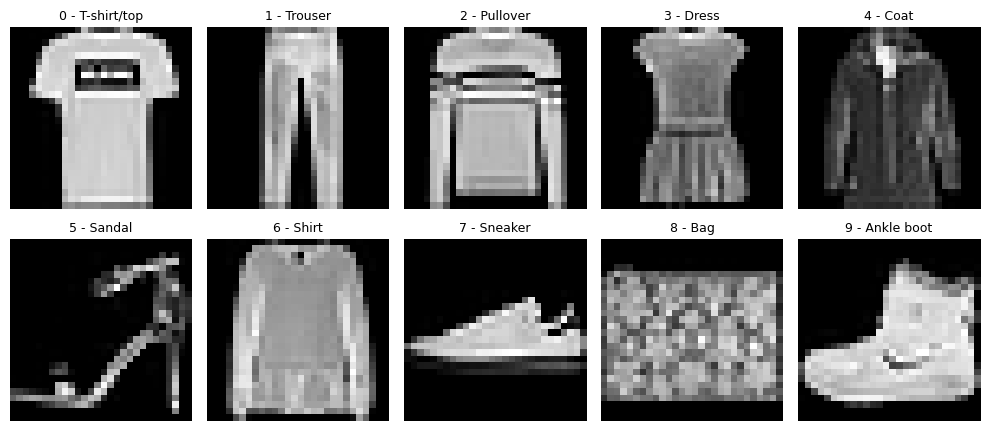

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.ravel()):
    idx = y_fm[y_fm == i].index[0]
    ax.imshow(X_fm.loc[idx].values.reshape(28, 28), cmap="gray")
    ax.set_title(f"{i} - {class_names[i]}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

### Identifikasi
- **Fitur (X):** 784 kolom (`pixel1` … `pixel784`), nilai intensitas 0–255 dari gambar 28×28.
- **Target (y):** kolom `label` bernilai 0–9 (10 jenis pakaian).
- **Tipe data:** **image** (gambar di-flatten menjadi baris tabel).

### Kesimpulan
Target punya **10 kelas** dan setiap gambar hanya masuk ke **1 kelas** → **Klasifikasi Multikelas**.

In [9]:
SAMPLE_PER_CLASS = 1000      # None = simpan data penuh (±130 MB, tidak bisa di-push ke GitHub biasa)

if SAMPLE_PER_CLASS:
    df_fm_save = (df_fm.groupby("label", group_keys=False)
                       .sample(n=SAMPLE_PER_CLASS, random_state=42)
                       .reset_index(drop=True))
else:
    df_fm_save = df_fm

df_fm_save.to_csv("data/fashion_mnist.csv", index=False)
print("Tersimpan:", pd.read_csv("data/fashion_mnist.csv").shape)

Tersimpan: (10000, 785)


---
# 3. Klasifikasi Multilabel — Yeast

### Asal dataset
- **Sumber asli:** Elisseeff & Weston (2002), *A kernel method for multi-labelled classification*, NIPS. Data berasal dari ekspresi gen ragi *Saccharomyces cerevisiae* (microarray).
- **Repositori multilabel:** MULAN — http://mulan.sourceforge.net/datasets-mlc.html (file `yeast.arff`)
- **Cara ambil di notebook ini:** OpenML `yeast` (data_id 40597) lewat `fetch_openml` (butuh koneksi internet).
- **Jangan tertukar:** dataset *Yeast* di UCI (1.484 data, 1 label lokasi protein) adalah versi **multikelas**. Versi multilabel (MULAN/OpenML) berisi 2.417 gen dengan 14 label fungsi.
- **Isi:** setiap gen punya 103 fitur ekspresi dan bisa memiliki **beberapa fungsi** (label) sekaligus.

In [10]:
from sklearn.datasets import fetch_openml

yeast = fetch_openml(data_id=40597, as_frame=True, parser="auto")
df_y_raw = yeast.frame
print(df_y_raw.shape)
print(list(df_y_raw.columns[:3]), "...", list(df_y_raw.columns[-16:]))

(2417, 117)
['Att1', 'Att2', 'Att3'] ... ['Att102', 'Att103', 'Class1', 'Class2', 'Class3', 'Class4', 'Class5', 'Class6', 'Class7', 'Class8', 'Class9', 'Class10', 'Class11', 'Class12', 'Class13', 'Class14']


In [11]:
# Pisahkan fitur & label (kolom label bernama Class1 ... Class14)
label_cols   = [c for c in df_y_raw.columns if str(c).lower().startswith("class")]
feature_cols = [c for c in df_y_raw.columns if c not in label_cols]

# Ubah ke DataFrame
X_y = df_y_raw[feature_cols].astype(float)                                   # FITUR
Y_y = (df_y_raw[label_cols].astype(str).apply(lambda s: s.str.upper().isin(["TRUE", "1"]))
       .astype(int))                                                         # LABEL (0/1 per kolom)
df_y = pd.concat([X_y, Y_y], axis=1)

df_y.iloc[:5, [0, 1, 2, -3, -2, -1]]

,Att1,Att2,Att3,Class12,Class13,Class14
0,0.004168,-0.170975,-0.156748,1,1,0
1,-0.103956,0.011879,-0.098986,0,0,0
2,0.509949,0.401709,0.293799,1,1,0
3,0.119092,0.004412,-0.002262,0,0,0
4,0.042037,0.007054,-0.069483,0,0,0


In [12]:
print("Jumlah data      :", df_y.shape[0])
print("Jumlah variabel  :", df_y.shape[1], "(", X_y.shape[1], "fitur +", Y_y.shape[1], "label )")
print("Missing value    :", int(df_y.isnull().sum().sum()))
print("Tipe data        : tabular numerik (ekspresi gen), bukan teks / image")
print()
print("Jumlah data per label:")
print(Y_y.sum().sort_values(ascending=False))
print()
labels_per_row = Y_y.sum(axis=1)
print("Rata-rata label per data:", round(labels_per_row.mean(), 2))
print("Data dengan >1 label    :", int((labels_per_row > 1).sum()), "dari", len(labels_per_row))

Jumlah data      : 2417
Jumlah variabel  : 117 ( 103 fitur + 14 label )
Missing value    : 0
Tipe data        : tabular numerik (ekspresi gen), bukan teks / image

Jumlah data per label:
Class12    1816
Class13    1799
Class2     1038
Class3      983
Class4      862
Class1      762
Class5      722
Class6      597
Class8      480
Class7      428
Class11     289
Class10     253
Class9      178
Class14      34
dtype: int64

Rata-rata label per data: 4.24
Data dengan >1 label    : 2385 dari 2417


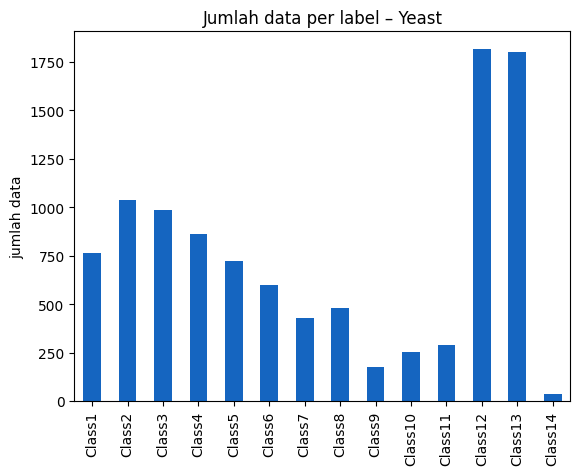

In [13]:
Y_y.sum().plot(kind="bar", color="#1565c0")
plt.title("Jumlah data per label – Yeast"); plt.ylabel("jumlah data"); plt.show()

### Identifikasi
- **Fitur (X):** 103 kolom numerik hasil ekspresi gen.
- **Target (y):** 14 kolom biner (`Class1` … `Class14`), nilai 1 jika gen memiliki fungsi tersebut.
- **Tipe data:** tabular numerik.

### Kesimpulan
Satu data bisa memiliki **lebih dari satu label sekaligus** (rata-rata > 1 label per gen) → **Klasifikasi Multilabel**.
Perbedaan dengan multikelas: pada multikelas satu data hanya boleh 1 kelas, pada multilabel label tidak saling meniadakan.

In [14]:
df_y.to_csv("data/yeast_multilabel.csv", index=False)
print("Tersimpan:", pd.read_csv("data/yeast_multilabel.csv").shape)

Tersimpan: (2417, 117)


---
# Ringkasan
| Dataset | Jenis | Tipe | Data | Fitur | Target |
|---|---|---|---|---|---|
| Breast Cancer Wisconsin | Biner | Tabular | 569 | 30 | 1 kolom, 2 kelas |
| Fashion-MNIST | Multikelas | Image | 70.000 (CSV sampel 10.000) | 784 piksel | 1 kolom, 10 kelas |
| Yeast | Multilabel | Tabular | 2.417 | 103 | 14 kolom label biner |

### Git commit & push (satu per dataset)
```bash
git add data/breast_cancer_wisconsin.csv Identifikasi_Dataset.ipynb
git commit -m "Tambah dataset klasifikasi biner: Breast Cancer Wisconsin"
git push

git add data/fashion_mnist.csv
git commit -m "Tambah dataset klasifikasi multikelas: Fashion-MNIST"
git push

git add data/yeast_multilabel.csv
git commit -m "Tambah dataset klasifikasi multilabel: Yeast"
git push
```

In [15]:
for f in sorted(os.listdir("data")):
    print(f"{f:35s} {os.path.getsize(os.path.join('data', f)) / 1e6:8.2f} MB")

breast_cancer_wisconsin.csv             0.12 MB
fashion_mnist.csv                      22.17 MB
yeast_multilabel.csv                    2.42 MB
